# Linear Algebra for Data Science 2026 — Lab 2, Core B
# Markov chains and PageRank

### <div align="right"> &copy; Rostyslav Hryniv, 2026, after O. Dyhdalovych & R. Hryniv, 2023 </div>

## Completed by:
*   Oleksandr Korniienko
*   Liubomyr Smerek

**Marked at the defence:** Core B is worth 2 points; the starred extension B1 at the end is one of three routes to the extension point (see the brief).

## Why this core

How popular is a web page, a paper or a user in a social network? PageRank answers with the stationary distribution of a random walk, which is an eigenvector of a huge, sparse, non-negative matrix. This core takes you from the naive model to the version that actually runs: you will see the model fail in three different ways, repair it with one rank-one term, **predict how fast the repaired iteration converges**, and run it on a graph with $10^5$ nodes without ever forming the matrix.

**Uses:** Lecture 3.2 (stochastic matrices, Perron–Frobenius, PageRank, power iteration). Core A's `power_method` is the same algorithm; here it gets a matrix-free form.

**Rules for this notebook**
* `np.linalg.eig`/`eigvals` are allowed **only to check** results on small graphs (§1, §3, §4). Your PageRank code must not call them.
* `networkx` is used for drawing small graphs, for generating the large test graph and, once, as an independent check in §5. Do not use it to compute ranks anywhere else.
* Every number you report must be reproduced by `Restart & Run All`.

In [1]:
import sys, time, numpy as np, scipy, scipy.sparse as sp, networkx as nx, matplotlib
import matplotlib.pyplot as plt
print('python', sys.version.split()[0], '| numpy', np.__version__, '| scipy', scipy.__version__,
      '| networkx', nx.__version__, '| matplotlib', matplotlib.__version__)
rng = np.random.default_rng(2026)   # do not change the seed: the defence uses your numbers

python 3.14.7 | numpy 2.4.6 | scipy 1.18.1 | networkx 3.7 | matplotlib 3.11.2


## The convention used throughout

Pages are numbered $0,\dots,n-1$. The **adjacency matrix** $G$ has
$$
G_{jk} = 1 \iff \text{page } k \text{ links to page } j,
$$
so **column $k$ lists the out-links of page $k$**, and the number of out-links $N_k$ is the $k$-th column sum. The link matrix of Lecture 3.2 is
$$
p_{jk} = \begin{cases} 1/N_k, & k \to j,\\ 0, & \text{otherwise,}\end{cases}
$$
so $p_{jk}$ is the probability of moving **from $k$ to $j$**, and every column of $P$ with $N_k > 0$ sums to $1$. Ranks are column vectors $\mathbf{r}$, updated by $\mathbf{r}_{n+1} = P\mathbf{r}_n$.

*(Last year's notebook stated this convention backwards in one place. If you find older material online, check its convention before reusing anything.)*

In [2]:
def plot_graph(G, ranks, title=''):
    # draws the graph with arrows k -> j for G[j, k] = 1, and the ranks under the labels
    graph = nx.from_numpy_array(np.asarray(G).T, create_using=nx.DiGraph)
    pos = nx.circular_layout(graph)
    plt.figure(figsize=(5, 4))
    nx.draw(graph, pos=pos, node_size=1600, node_color='w', edgecolors='k', linewidths=2,
            connectionstyle='arc3,rad=0.1', arrowsize=18)
    nx.draw_networkx_labels(graph, pos=pos, labels={v: f'{v}\n{ranks[v]:.3f}' for v in graph.nodes()})
    plt.title(title); plt.show()

---
## 1. The random surfer

### 1.1 Implement the two building blocks
* `link_matrix(G)` returns $P$ as above. Columns of pages with no out-links ("dead ends") stay zero for now.
* `power_markov(M, r0, tol, max_iter)` iterates $\mathbf{r}_{n+1} = M\mathbf{r}_n$. Here `M` may be a matrix **or a function** `x -> M x`; that is what will let you reuse it unchanged in §5. Stop when $\|\mathbf{r}_{n+1} - \mathbf{r}_n\|_1 \le$ `tol`. Return the final vector and a history with the 1-norm increments and the sums $\mathbf{1}^\top\mathbf{r}_n$.

**Question 1.1.** Core A normalised the iterate at every step. Why is no normalisation needed here, as long as $M$ is column-stochastic?

Each column of $M$ sums to 1, so each page distributes all its probability through its links. The total probability stays 1, and all values stay non-negative. Therefore, starting from a probability distribution, we do not need to normalise after each step.


In [3]:
def link_matrix(G):
    """Dense link matrix; columns for dead ends stay zero."""
    G = np.asarray(G, dtype=float)
    out_degree = G.sum(axis=0)
    return np.divide(G, out_degree, out=np.zeros_like(G), where=out_degree != 0)


def power_markov(M, r0=None, tol=1e-10, max_iter=1000):
    """Iterate r <- M r for a dense/sparse matrix or callable.

    Returns r and history: 'inc' contains the L1 changes after each step;
    'sum' contains total mass, including the initial distribution.
    For a callable without a shape attribute, supply r0 explicitly.
    """
    if r0 is None:
        if not hasattr(M, 'shape'):
            raise ValueError('Supply r0 when M has no shape (e.g. a function).')
        r = np.full(M.shape[0], 1.0 / M.shape[0])
    else:
        r = np.array(r0, dtype=float, copy=True)

    matvec = M if callable(M) else lambda x: M @ x
    increments = []
    sums = [r.sum()]
    for _ in range(max_iter):
        r_new = np.asarray(matvec(r), dtype=float).reshape(-1)
        increment = np.linalg.norm(r_new - r, ord=1)
        increments.append(increment)
        sums.append(r_new.sum())
        r = r_new
        if increment <= tol:
            break

    return r, {'inc': np.array(increments), 'sum': np.array(sums)}

### 1.2 First test
Run the iteration on the graph below from the uniform distribution and from two other starting distributions of your choice. Check the result against the eigenvector of $P$ for $\lambda = 1$ obtained from `np.linalg.eig` (normalise it to sum 1). Which page ranks highest? Explain *from the graph* why that is reasonable.

P =
 [[0.         0.33333333 0.5        0.        ]
 [0.5        0.         0.5        1.        ]
 [0.         0.33333333 0.         0.        ]
 [0.5        0.33333333 0.         0.        ]]
Column sums: [1. 1. 1. 1.]
uniform        : ranks=[0.20689655 0.4137931  0.13793103 0.24137931], steps=62, L1 eigenvector difference=3.46e-11
all at page 0  : ranks=[0.20689655 0.4137931  0.13793103 0.24137931], steps=63, L1 eigenvector difference=2.85e-11
all at page 3  : ranks=[0.20689655 0.4137931  0.13793103 0.24137931], steps=67, L1 eigenvector difference=2.95e-11
Eigenvector check: [0.20689655 0.4137931  0.13793103 0.24137931]


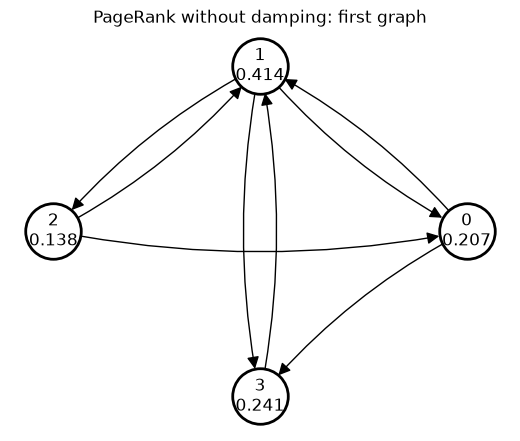

In [4]:
G1 = np.array([[0, 1, 1, 0],
               [1, 0, 1, 1],
               [0, 1, 0, 0],
               [1, 1, 0, 0]])
P1 = link_matrix(G1)
print('P =\n', P1)
print('Column sums:', P1.sum(axis=0))

# Independent check only: PageRank itself uses repeated multiplication.
eigenvalues, eigenvectors = np.linalg.eig(P1)
idx = np.argmin(np.abs(eigenvalues - 1))
r_eig = eigenvectors[:, idx].real
r_eig /= r_eig.sum()

starts = {
    'uniform': np.full(4, 0.25),
    'all at page 0': np.array([1., 0., 0., 0.]),
    'all at page 3': np.array([0., 0., 0., 1.]),
}
results1 = {}
for name, r0 in starts.items():
    r, history = power_markov(P1, r0)
    results1[name] = (r, history)
    print(f'{name:15s}: ranks={np.round(r, 8)}, '
          f'steps={len(history["inc"])}, '
          f'L1 eigenvector difference={np.linalg.norm(r - r_eig, 1):.2e}')
    assert history['inc'][-1] <= 1e-10
    assert np.allclose(history['sum'], 1)
    assert np.linalg.norm(r - r_eig, 1) < 1e-9

print('Eigenvector check:', np.round(r_eig, 8))
plot_graph(G1, results1['uniform'][0], 'PageRank without damping: first graph')

All three starting distributions give the same ranks for pages 0, 1, 2, and 3: approximately **0.207, 0.414, 0.138, and 0.241**. These match the eigenvector for eigenvalue 1, normalised to sum to 1.

**Page 1 ranks highest** because every other page links to it. Pages 0 and 2 each send half their rank to page 1, while page 3 sends all its rank there.


---
## 2. Dead ends

### 2.1 What goes wrong
In the graph `G2` below, page 3 has no out-links. Run the iteration and plot the sums $\mathbf{1}^\top\mathbf{r}_n$ against $n$. Explain what you see using the column sums of $P$: show that $\mathbf{1}^\top\mathbf{r}_{n+1} = \mathbf{1}^\top\mathbf{r}_n - \mathbf{d}^\top\mathbf{r}_n$, where $\mathbf{d}$ marks the dead ends ($d_k = 1$ if $N_k = 0$, else $0$).

### 2.2 The repair
Let the surfer jump from a dead end to a uniformly random page:
$$
P_d := P + \tfrac1n\,\mathbf{1}\mathbf{d}^\top .
$$
Implement `fix_dead_ends(P)` and rerun. Check that $P_d$ is column-stochastic.

Original column sums: [1. 1. 1. 0.]
Fixed column sums:    [1. 1. 1. 1.]
Final total rank without fix: 1.558e-10
Final total rank with fix:    1.0000000000
Fixed ranks: [0.252632 0.284211 0.168421 0.294737]


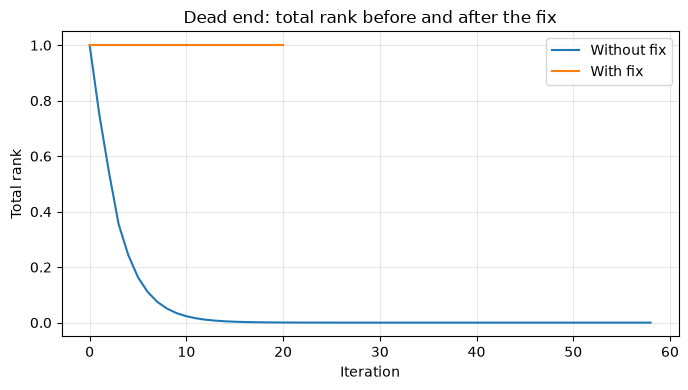

In [5]:
G2 = np.array([[0, 1, 1, 0],
               [1, 0, 1, 0],
               [0, 1, 0, 0],
               [1, 1, 0, 0]])

def fix_dead_ends(P):
    """Replace zero columns with uniform probabilities (small dense graphs)."""
    P = np.asarray(P, dtype=float)
    d = (P.sum(axis=0) == 0).astype(float)
    n = P.shape[0]
    return P + np.outer(np.ones(n) / n, d)

P2 = link_matrix(G2)
P2_fixed = fix_dead_ends(P2)
r2, history2 = power_markov(P2)
r2_fixed, history2_fixed = power_markov(P2_fixed)

print('Original column sums:', P2.sum(axis=0))
print('Fixed column sums:   ', P2_fixed.sum(axis=0))
print(f'Final total rank without fix: {r2.sum():.3e}')
print(f'Final total rank with fix:    {r2_fixed.sum():.10f}')
print('Fixed ranks:', np.round(r2_fixed, 6))

assert np.all(P2_fixed >= 0)
assert np.allclose(P2_fixed.sum(axis=0), 1)
assert np.allclose(history2_fixed['sum'], 1)

plt.figure(figsize=(7, 4))
plt.plot(history2['sum'], label='Without fix')
plt.plot(history2_fixed['sum'], label='With fix')
plt.xlabel('Iteration')
plt.ylabel('Total rank')
plt.title('Dead end: total rank before and after the fix')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Page 3 has no outgoing links, so its column in $P$ is zero. Any rank that reaches it disappears on the next step. The plot shows the total rank falling towards zero.

The other columns sum to 1, while dead-end columns sum to 0. Thus $\mathbf{1}^\top P=\mathbf{1}^\top-\mathbf{d}^\top$, which gives
$$\mathbf{1}^\top r_{t+1}=(\mathbf{1}^\top-\mathbf{d}^\top)r_t=\mathbf{1}^\top r_t-\mathbf{d}^\top r_t.$$
In simple words: the next total equals the current total minus the rank at dead ends.

The fix replaces each zero column with $1/n$ in every entry. Here, page 3 sends a quarter of its rank to each of the four pages, including itself. Now every column sums to 1, so no probability is lost. The total rank stays 1, and the ranks settle at approximately **0.253, 0.284, 0.168, and 0.295** for pages 0–3.


---
## 3. When the answer is not unique, or the iteration does not settle

### 3.1 Three graphs, three problems
Run `power_markov` (on $P_d$) for the three graphs below, each from **at least three** starting distributions: the uniform one, $\mathbf{e}_0$, and one more. Use `max_iter=200`. For each graph, describe what happens. Then compute the eigenvalues of $P_d$ (here you may use `np.linalg.eigvals`), plot them in the complex plane together with the unit circle, and explain each behaviour **from the spectrum**.

* `G6`: does every page get a sensible rank? Does the iteration converge from every start?
* `G4` (a directed cycle): why does the uniform start *seem* to converge immediately?
* `G2c` (two separate parts): does the limit depend on the start?


G6
  uniform   : settled=True, steps=135, last change=8.631e-11, ranks=[0.5 0.5 0.  0.  0.  0. ]
  page 0    : settled=False, steps=200, last change=2.000e+00, ranks=[1. 0. 0. 0. 0. 0.]
  last page : settled=False, steps=200, last change=6.667e-01, ranks=[0.333333 0.666667 0.       0.       0.       0.      ]
  Eigenvalues: [ 1.      +0.j       -1.      +0.j        0.851383+0.j
 -0.      +0.j       -0.425692+0.458592j -0.425692-0.458592j]

G4
  uniform   : settled=True, steps=  1, last change=0.000e+00, ranks=[0.25 0.25 0.25 0.25]
  page 0    : settled=False, steps=200, last change=2.000e+00, ranks=[1. 0. 0. 0.]
  last page : settled=False, steps=200, last change=2.000e+00, ranks=[0. 0. 0. 1.]
  Eigenvalues: [-1.+0.j  0.+1.j  0.-1.j  1.+0.j]

G2c
  uniform   : settled=True, steps= 65, last change=7.761e-11, ranks=[0.2 0.1 0.2 0.2 0.1 0.2]
  page 0    : settled=True, steps= 70, last change=5.821e-11, ranks=[0.4 0.2 0.4 0.  0.  0. ]
  last page : settled=True, steps= 71, last change=5.8

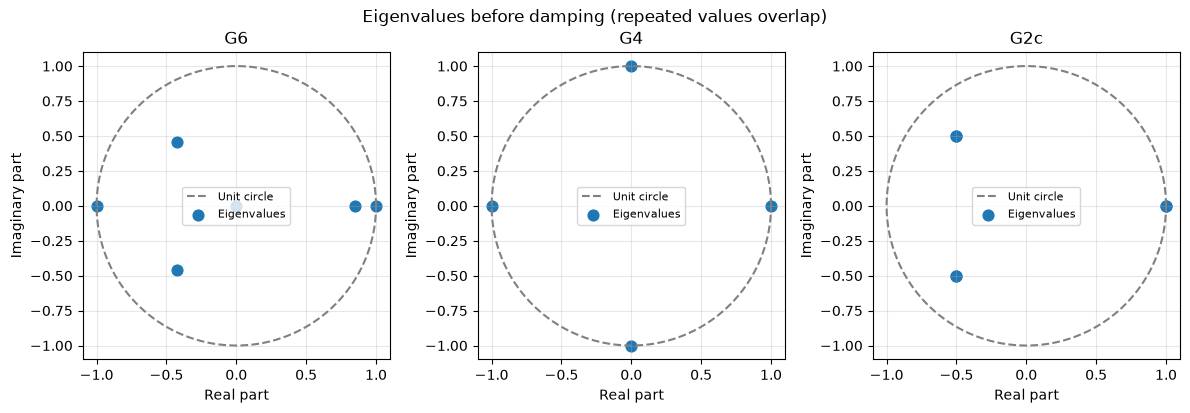

In [6]:
G6 = np.array([[0, 1, 0, 0, 0, 1],
               [1, 0, 1, 0, 0, 0],
               [0, 0, 0, 1, 0, 0],
               [0, 0, 1, 0, 1, 1],
               [0, 0, 1, 0, 0, 1],
               [0, 0, 0, 1, 0, 0]])
G4 = np.array([[0, 1, 0, 0],
               [0, 0, 1, 0],
               [0, 0, 0, 1],
               [1, 0, 0, 0]])
G2c = np.zeros((6, 6), dtype=int)
for k, j in [(0, 1), (1, 2), (2, 0), (0, 2), (3, 4), (4, 5), (5, 3), (3, 5)]:   # link k -> j
    G2c[j, k] = 1

graphs3 = {'G6': G6, 'G4': G4, 'G2c': G2c}
starts3 = {}
results3 = {}
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
theta = np.linspace(0, 2 * np.pi, 300)
for ax, (name, G) in zip(axes, graphs3.items()):
    n = G.shape[0]
    starts3[name] = {'uniform': np.full(n, 1 / n),
                     'page 0': np.eye(n)[0], 'last page': np.eye(n)[-1]}
    Pd = fix_dead_ends(link_matrix(G))
    results3[name] = {}
    print(f'\n{name}')
    for start_name, r0 in starts3[name].items():
        r, history = power_markov(Pd, r0, max_iter=200)
        results3[name][start_name] = (r, history)
        settled = history['inc'][-1] <= 1e-10
        print(f'  {start_name:10s}: settled={settled}, steps={len(history["inc"]):3d}, '
              f'last change={history["inc"][-1]:.3e}, ranks={np.round(r, 6)}')
    eigenvalues = np.linalg.eigvals(Pd)
    print('  Eigenvalues:', np.round(eigenvalues, 6))
    ax.plot(np.cos(theta), np.sin(theta), '--', color='gray', label='Unit circle')
    ax.scatter(eigenvalues.real, eigenvalues.imag, s=60, label='Eigenvalues')
    ax.set(title=name, xlabel='Real part', ylabel='Imaginary part')
    ax.set_aspect('equal')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle('Eigenvalues before damping (repeated values overlap)')
plt.tight_layout()
plt.show()

**G6:** Pages 0 and 1 form a trap: once the surfer enters, they cannot leave. The ranks of pages 2–5 tend to zero. The eigenvalue $-1$ causes probability to keep alternating between pages 0 and 1, so the iteration does not converge from every start. In our tests, the uniform start converges, but the two single-page starts keep oscillating. Eigenvalue 1 gives the stationary distribution $(0.5,0.5,0,0,0,0)^\top$, but having a stationary distribution does not mean every iteration settles.

**G4:** The eigenvalues are $1,-1,i,-i$, all on the unit circle. Probability keeps moving around the cycle without settling. The uniform start stops immediately because it is already stationary: moving equal probabilities around changes nothing. Starting at one page shows the cycling clearly.

**G2c:** The two groups have no links between them, so probability cannot move from one group to the other. Eigenvalue 1 occurs twice, which allows different stationary distributions. The other eigenvalues have modulus less than 1, so each group settles internally. The final ranks depend on the start: the uniform start keeps half the probability in each group, while starting at page 0 or page 5 keeps all of it in that page's group.

### 3.2 The repair: damping
With $0 < \alpha < 1$ (Google's choice was $\alpha \approx 0.85$), the surfer follows a link with probability $\alpha$ and jumps to a uniformly random page with probability $1-\alpha$:
$$
\widetilde P := \alpha P_d + \frac{1-\alpha}{n}\,\mathbf{1}\mathbf{1}^\top .
$$
*Careful: here, as in the lecture, $\alpha$ is the probability of **following a link**. Last year's notebook used $\alpha$ for the jump probability, i.e. our $1-\alpha$.*

**(a)** Show that $\widetilde P$ is column-stochastic and entrywise positive. What does Perron–Frobenius (Lecture 3.2) then guarantee?

**(b)** Prove the bound from the lecture: every eigenvalue $\lambda \ne 1$ of $\widetilde P$ satisfies $|\lambda| \le \alpha$. *Hint:* let $\widetilde P\mathbf{w} = \lambda\mathbf{w}$ with $\lambda \ne 1$. Use $\mathbf{1}^\top\widetilde P = \mathbf{1}^\top$ to show that $\mathbf{1}^\top\mathbf{w} = 0$, and conclude that $\lambda/\alpha$ is an eigenvalue of $P_d$. Why can no eigenvalue of a column-stochastic matrix exceed 1 in modulus? *(Consider the norm $\|\cdot\|_1$.)*

**(a)** Each column of $P_d$ sums to 1. Therefore each column of $\widetilde P$ sums to
$$\alpha+(1-\alpha)=1.$$
Every entry is at least $(1-\alpha)/n>0$. By Perron–Frobenius, there is one stationary distribution, all its ranks are positive, and eigenvalue 1 is simple. All other eigenvalues have modulus less than 1, so the iteration converges to this distribution from any starting probability distribution.

**(b)** Suppose $\widetilde P w=\lambda w$ with $w\ne0$ and $\lambda\ne1$. Since columns sum to 1,
$$\mathbf{1}^\top w=\mathbf{1}^\top\widetilde P w=\lambda\mathbf{1}^\top w.$$
Thus $\mathbf{1}^\top w=0$. The random-jump term vanishes when applied to $w$, leaving
$$\alpha P_d w=\lambda w,\qquad P_d w=\frac{\lambda}{\alpha}w.$$
For a non-negative column-stochastic matrix, $\|P_d\|_1=1$ (the largest column sum). Therefore
$$\frac{|\lambda|}{\alpha}\|w\|_1=\|P_d w\|_1\le\|P_d\|_1\|w\|_1=\|w\|_1.$$
Dividing by $\|w\|_1>0$ gives **$|\lambda|\le\alpha$**. This means the modes other than the stationary one decay rather than persist.

### 3.3 Implement and test
Write `google_matrix(G, alpha)` (dense — small graphs only) and rerun the three graphs of §3.1 from the same starts. Does the iteration converge now, and to a unique answer? Then, for `G6`, tabulate the ranks for $\alpha \in \{0.5, 0.85, 0.99\}$. What happens to pages 2–5 as $\alpha \to 1$, and why?

In [7]:
def google_matrix(G, alpha=0.85):
    """Dense PageRank matrix with dead-end repair and random jumps."""
    if not 0 < alpha < 1:
        raise ValueError('alpha must be between 0 and 1.')
    Pd = fix_dead_ends(link_matrix(G))
    n = Pd.shape[0]
    return alpha * Pd + (1 - alpha) * np.ones((n, n)) / n

results3_damped = {}
for name, G in graphs3.items():
    M = google_matrix(G)
    assert np.all(M > 0) and np.allclose(M.sum(axis=0), 1)
    results3_damped[name] = {}
    print(f'\n{name}, alpha=0.85')
    for start_name, r0 in starts3[name].items():
        r, history = power_markov(M, r0, max_iter=200)
        results3_damped[name][start_name] = (r, history)
        print(f'  {start_name:10s}: steps={len(history["inc"]):3d}, '
              f'ranks={np.round(r, 6)}')
        assert history['inc'][-1] <= 1e-10
        assert np.allclose(history['sum'], 1)
    reference = results3_damped[name]['uniform'][0]
    for r, _ in results3_damped[name].values():
        assert np.linalg.norm(r - reference, 1) < 1e-9

print('\nG6 ranks as alpha changes:')
print('alpha ' + ' '.join(f'  page {j}' for j in range(6)) + '   steps')
for alpha in [0.5, 0.85, 0.99]:
    # Allow extra steps for damping values close to 1.
    r, history = power_markov(google_matrix(G6, alpha), max_iter=5000)
    assert history['inc'][-1] <= 1e-10
    print(f'{alpha:5.2f} ' + ' '.join(f'{value:9.6f}' for value in r)
          + f'   {len(history["inc"]):5d}')


G6, alpha=0.85
  uniform   : steps= 67, ranks=[0.318798 0.318798 0.08054  0.130683 0.07064  0.08054 ]
  page 0    : steps=147, ranks=[0.318798 0.318798 0.08054  0.130683 0.07064  0.08054 ]
  last page : steps=140, ranks=[0.318798 0.318798 0.08054  0.130683 0.07064  0.08054 ]

G4, alpha=0.85
  uniform   : steps=  1, ranks=[0.25 0.25 0.25 0.25]
  page 0    : steps=147, ranks=[0.25 0.25 0.25 0.25]
  last page : steps=147, ranks=[0.25 0.25 0.25 0.25]

G2c, alpha=0.85
  uniform   : steps= 45, ranks=[0.193895 0.107405 0.1987   0.193895 0.107405 0.1987  ]
  page 0    : steps=132, ranks=[0.193895 0.107405 0.1987   0.193895 0.107405 0.1987  ]
  last page : steps=132, ranks=[0.193895 0.107405 0.1987   0.193895 0.107405 0.1987  ]

G6 ranks as alpha changes:
alpha   page 0   page 1   page 2   page 3   page 4   page 5   steps
 0.50  0.210317  0.210317  0.130952  0.190476  0.126984  0.130952      26
 0.85  0.318798  0.318798  0.080540  0.130683  0.070640  0.080540      67
 0.99  0.478722  0.478722 

With $\alpha=0.85$, all three graphs converge from all three starts. For each graph, the starts give the same final ranks, and every page has a positive rank. Random jumps let the surfer leave traps, break cycles, and move between separate groups.

For G6, increasing $\alpha$ puts more rank on pages 0 and 1. As $\alpha\to1$, the ranks of pages 2–5 tend to zero, while pages 0 and 1 each approach 0.5. This happens because random jumps become rarer: links lead into the trap, but only a random jump can take the surfer out. Convergence also becomes slower, as the table shows.

---
## 4. How fast? Predict, then measure

By §3.2(b), the error of power iteration on $\widetilde P$ shrinks by at least the factor $\alpha$ per step.

**(a) Predict.** How many iterations should it take for the increment $\|\mathbf{r}_{n+1}-\mathbf{r}_n\|_1$ to fall from about $1$ to $10^{-10}$ for $\alpha = 0.85$? For $\alpha = 0.99$? Write the numbers down before you run anything.

If the increment starts around 1 and shrinks by a factor of $\alpha$ per step, we need $\alpha^k\le10^{-10}$. Thus
$$k\ge\frac{\log(10^{-10})}{\log(\alpha)}.$$
Rounding up gives **142 steps for $\alpha=0.85$** and **2292 steps for $\alpha=0.99$**.
These are worst-case estimates for an initial increment of 1. The actual iteration may be faster if the graph has smaller non-stationary eigenvalues or the start does not excite the slowest mode.

**(b) Measure.** The cell below generates a random directed graph with $n = 300$ pages, average out-degree about 5 and some dead ends. For $\alpha \in \{0.5, 0.7, 0.85, 0.95, 0.99\}$ compute
* the measured rate: the median of the ratios of successive increments, taken over the steps where the increment lies between $10^{-3}$ and $10^{-9}$;
* $|\lambda_2(\widetilde P)|$ from `np.linalg.eigvals` (the largest modulus apart from $\lambda = 1$);
* the bound $\alpha$.

Show a table and a plot of the increments against $n$. Is the bound $\alpha$ attained? Compute $|\lambda_2(\widetilde P)|/\alpha$ for each $\alpha$: what do you notice?

**(c) When is the bound sharp?** Repeat the measurement for `G2c` from §3. Explain the difference using the proof of §3.2(b). Real web graphs contain many pages and groups of pages with no links out of the group. Which of the two cases is the realistic one?


Random graph (start: uniform)
alpha   steps   measured rate   |lambda2|   bound   |lambda2|/alpha
 0.50      17        0.245049    0.249991    0.50          0.499982
 0.70      21        0.341901    0.349988    0.70          0.499982
 0.85      26        0.415124    0.424985    0.85          0.499982
 0.95      29        0.449279    0.474983    0.95          0.499982
 0.99      31        0.476580    0.494982    0.99          0.499982

G2c (start: page 0)
alpha   steps   measured rate   |lambda2|   bound   |lambda2|/alpha
 0.50      34        0.500000    0.500000    0.50          1.000000
 0.70      63        0.700000    0.700000    0.70          1.000000
 0.85     132        0.850000    0.850000    0.85          1.000000
 0.95     392        0.950000    0.950000    0.95          1.000000
 0.99    1834        0.990000    0.990000    0.99          1.000000


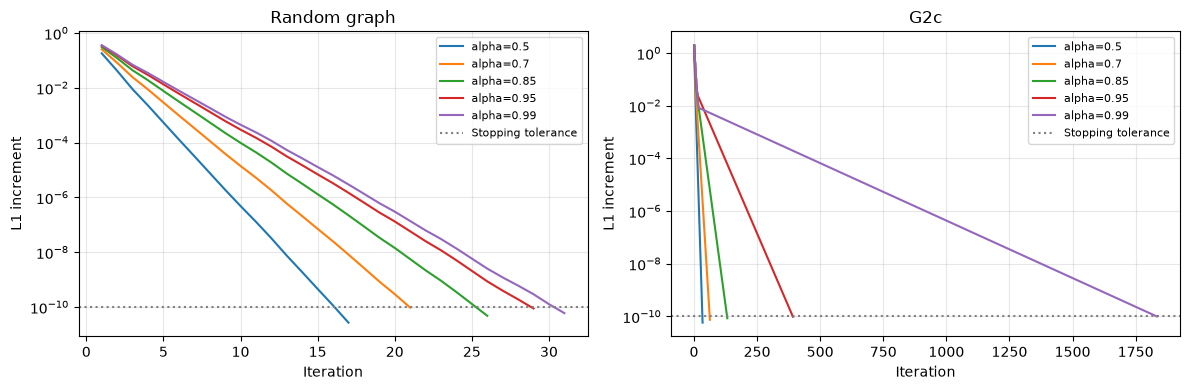

In [8]:
n = 300
A_rand = (rng.random((n, n)) < 5 / n).astype(int)
np.fill_diagonal(A_rand, 0)
A_rand[:, rng.choice(n, 15, replace=False)] = 0     # 15 dead ends

alphas4 = [0.5, 0.7, 0.85, 0.95, 0.99]
results4 = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, G) in zip(axes, [('Random graph', A_rand), ('G2c', G2c)]):
    # Starting in just one group makes G2c's slow exchange of mass visible.
    r0 = np.full(G.shape[0], 1 / G.shape[0]) if name == 'Random graph' else np.eye(6)[0]
    results4[name] = []
    print(f'\n{name} (start: {"uniform" if name == "Random graph" else "page 0"})')
    print('alpha   steps   measured rate   |lambda2|   bound   |lambda2|/alpha')
    for alpha in alphas4:
        M = google_matrix(G, alpha)
        r, history = power_markov(M, r0, max_iter=5000)
        inc = history['inc']
        # Use ratios inc[k+1]/inc[k] whose denominator is in the requested window.
        mask = (inc[:-1] >= 1e-9) & (inc[:-1] <= 1e-3)
        rate = np.median(inc[1:][mask] / inc[:-1][mask])
        eigenvalues = np.linalg.eigvals(M)
        stationary_index = np.argmin(np.abs(eigenvalues - 1))
        lambda2 = np.max(np.abs(np.delete(eigenvalues, stationary_index)))
        results4[name].append({'alpha': alpha, 'steps': len(inc),
                               'rate': rate, 'lambda2': lambda2,
                               'scaled_lambda2': lambda2 / alpha})
        print(f'{alpha:5.2f} {len(inc):7d} {rate:15.6f} {lambda2:11.6f} '
              f'{alpha:7.2f} {lambda2 / alpha:17.6f}')
        assert mask.any()
        assert inc[-1] <= 1e-10
        assert lambda2 <= alpha + 1e-10
        ax.semilogy(np.arange(1, len(inc) + 1), inc, label=f'alpha={alpha}')
    ax.axhline(1e-10, color='gray', linestyle=':', label='Stopping tolerance')
    ax.set(title=name, xlabel='Iteration', ylabel='L1 increment')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Random graph:** The measured rates are close to $|\lambda_2|$ and clearly below $\alpha$, so the bound is not reached. The iteration is faster than the worst-case prediction. Small differences between the measured rate and $|\lambda_2|$ are expected: we measure a finite range of steps, and several eigenmodes can contribute.

The ratio $|\lambda_2|/\alpha$ is approximately **0.499982** for every tested $\alpha$. The reason is the proof in §3.2: damping multiplies the eigenvalues on the zero-sum subspace by $\alpha$. The underlying graph stays the same, so this ratio stays the same.

**G2c:** Here $|\lambda_2|=\alpha$, and the measured rate is close to $\alpha$. Before damping, eigenvalue 1 occurs twice because the groups are disconnected. Their difference gives a zero-sum eigenvector, whose eigenvalue becomes $\alpha$ after damping. This makes the bound sharp: only random jumps can move probability between the groups.

We start G2c at page 0 to show this effect. A uniform start already puts the correct total probability in each group, so it misses this slow mode and converges faster.

**Real web graphs:** G2c is the more relevant case for the slow convergence caused by closed groups. Such groups can keep non-stationary eigenvalues at or near 1 before damping, making the damped rate equal or close to $\alpha$. The bound is therefore useful even when a well-connected random graph converges much faster.

---
## 5. Matrix-free PageRank on $10^5$ pages

### 5.1 The graph
The cell below builds a directed graph with about $10^5$ pages and stores its adjacency matrix in sparse form, with our convention $G_{jk} = 1 \iff k\to j$. It has two parts:
* $100\,000$ pages generated by `networkx.scale_free_graph`, a standard model of web-like graphs with a few very popular pages;
* $300$ **spider traps**: groups of three pages that receive one link from the main graph but link only among themselves — the structure of pages 0–1 in `G6`, and common on the real web (link farms, closed sites).

`[TBD: replace by a real web or citation graph once the dataset is decided; the code below should then only need a different loader.]`

**Question 5.1.** How much memory would the dense matrix $\widetilde P$ need in double precision? How much does the sparse $G$ need (look at `G.data.nbytes + G.indices.nbytes + G.indptr.nbytes`)?

In [9]:
t0 = time.time()
g = nx.DiGraph(nx.scale_free_graph(100_000, seed=2026))
g.remove_edges_from(nx.selfloop_edges(g))
for t in range(300):                                   # spider traps: a, b, c link only among themselves
    a, b, c = 100_000 + 3 * t + np.arange(3)
    g.add_edges_from([(a, b), (b, c), (c, a), (a, c)])
    g.add_edge(int(rng.integers(100_000)), a)          # one way in, no way out
n_big = g.number_of_nodes()
G_big = nx.to_scipy_sparse_array(g, format='csr', dtype=float).T.tocsc()   # G[j, k] = 1 iff k -> j
print(f'{n_big} pages, {G_big.nnz} links, built in {time.time() - t0:.1f} s')
dense_bytes = n_big ** 2 * np.dtype(np.float64).itemsize
sparse_bytes = G_big.data.nbytes + G_big.indices.nbytes + G_big.indptr.nbytes
print(f'Dense float64 matrix: {dense_bytes:,} bytes ({dense_bytes / 1e9:.3f} GB)')
print(f'Sparse adjacency:     {sparse_bytes:,} bytes ({sparse_bytes / 1e6:.3f} MB)')

100900 pages, 194086 links, built in 1.4 s
Dense float64 matrix: 81,446,480,000 bytes (81.446 GB)
Sparse adjacency:     3,912,584 bytes (3.913 MB)


There are **100,900 pages**. A dense float64 matrix needs $n^2 \times 8$ bytes: **81.446 GB** (about 75.85 GiB).

The sparse adjacency arrays use only **3.913 MB**, because they store existing links instead of every possible pair of pages. This counts the sparse matrix arrays, not the NetworkX graph or the whole program.

### 5.2 Never form $\widetilde P$
Show that
$$
\widetilde P\mathbf{x} = \alpha P\mathbf{x} + \frac{\alpha\,(\mathbf{d}^\top\mathbf{x}) + (1-\alpha)\,(\mathbf{1}^\top\mathbf{x})}{n}\,\mathbf{1},
$$
so one step costs one sparse matrix-vector product plus $O(n)$. Then implement `google_matvec(G, alpha)`, which builds the sparse $P$ and the vector $\mathbf{d}$ **once** and returns a function `x -> P_tilde @ x`. Scale the columns of $G$ with a sparse diagonal matrix (`sp.diags`), not with a loop.

Substitute $P_d=P+\frac1n\mathbf{1}\mathbf{d}^\top$ into the damped matrix and multiply by $x$:
$$\widetilde P x=\alpha Px+\frac{\alpha}{n}\mathbf{1}(\mathbf{d}^\top x)+\frac{1-\alpha}{n}\mathbf{1}(\mathbf{1}^\top x).$$
Combining the last two terms gives the required formula.

First, move probability along links using the sparse matrix. Then share the dead-end probability and random-jump probability equally among all pages. We only need one sparse matrix-vector product and a few vector operations: $O(m+n)$ work, where $m$ is the number of links. We never build the dense Google matrix.

In [10]:
def google_matvec(G, alpha=0.85):
    """Build sparse link probabilities once; return the PageRank update."""
    if not 0 < alpha < 1:
        raise ValueError('alpha must be between 0 and 1.')
    G = sp.csc_array(G, dtype=float)
    n = G.shape[0]
    out_degree = np.asarray(G.sum(axis=0)).ravel()
    d = out_degree == 0
    inverse_degree = np.divide(1.0, out_degree, out=np.zeros(n), where=~d)
    P = G @ sp.diags(inverse_degree)

    def matvec(x):
        x = np.asarray(x, dtype=float)
        shared = (alpha * x[d].sum() + (1 - alpha) * x.sum()) / n
        return alpha * (P @ x) + shared

    return matvec

### 5.3 Run it
1. Check `google_matvec` against `google_matrix` on `A_rand` from §4 (same $\alpha$, random $\mathbf{x}$).
2. Run `power_markov` with `google_matvec(G_big, 0.85)`, `tol=1e-10`, `r0` uniform. Report the number of iterations, the time per iteration, and compare the iteration count with the bound from §4(a) and with the measured rate. Which feature of this graph decides the rate? *(Optional check: drop the traps and rerun.)*
4. How much total rank sits in the 900 trap pages, although they are under 1% of the pages?
3. Independent check: compare your ranks with `nx.pagerank(g, alpha=0.85, tol=1e-12)` in the 1-norm. (Both use the same dead-end rule.)

In [11]:
# A separate generator keeps this check from changing the notebook's rng state.
x_check = np.random.default_rng(2026).random(A_rand.shape[0])
sparse_result = google_matvec(sp.csc_array(A_rand), 0.85)(x_check)
dense_result = google_matrix(A_rand, 0.85) @ x_check
matvec_difference = np.linalg.norm(sparse_result - dense_result, 1)
print(f'Small-graph dense/sparse L1 difference: {matvec_difference:.3e}')
assert np.allclose(sparse_result, dense_result)

big_matvec = google_matvec(G_big, 0.85)
start = time.perf_counter()
r_big, history_big = power_markov(big_matvec, np.full(n_big, 1 / n_big),
                                   tol=1e-10, max_iter=1000)
elapsed_big = time.perf_counter() - start
steps_big = len(history_big['inc'])
inc_big = history_big['inc']
window_big = (inc_big[:-1] >= 1e-9) & (inc_big[:-1] <= 1e-3)
rate_big = np.median(inc_big[1:][window_big] / inc_big[:-1][window_big])
assert inc_big[-1] <= 1e-10
assert np.allclose(history_big['sum'], 1)
assert np.all(r_big >= 0)

# Use the same node order as the sparse adjacency matrix.
nodes_big = np.array(list(g.nodes()))
trap_mask = nodes_big >= 100_000
trap_rank = r_big[trap_mask].sum()
print(f'Iterations: {steps_big}; prediction from Part 4(a): 142')
print(f'Total iteration time: {elapsed_big:.4f} s; '
      f'mean time per iteration: {elapsed_big / steps_big * 1000:.4f} ms')
print(f'Measured rate: {rate_big:.6f}; bound: 0.85')
print(f'Trap pages: {trap_mask.sum()} ({trap_mask.mean():.4%} of pages)')
print(f'Total trap rank: {trap_rank:.6f} ({trap_rank:.4%} of rank)')

nx_ranks = nx.pagerank(g, alpha=0.85, tol=1e-12)
r_nx = np.array([nx_ranks[node] for node in nodes_big])
nx_difference = np.linalg.norm(r_big - r_nx, 1)
print(f'L1 difference from NetworkX: {nx_difference:.3e}')
# NetworkX stops at n * tol, so its tolerance differs from ours.
assert nx_difference < 1e-6

Small-graph dense/sparse L1 difference: 1.613e-14
Iterations: 110; prediction from Part 4(a): 142
Total iteration time: 0.1136 s; mean time per iteration: 1.0327 ms
Measured rate: 0.846023; bound: 0.85
Trap pages: 900 (0.8920% of pages)
Total trap rank: 0.032744 (3.2744% of rank)
L1 difference from NetworkX: 5.001e-07


### 5.4 What does the ranking say?
List the ten top pages by PageRank and the ten top pages by **in-degree** (number of in-links). How many pages are on both lists? Find one page that ranks much higher by PageRank than by in-degree, look at who links to it, and explain the difference in one or two sentences.

In [12]:
in_degree_big = np.asarray(G_big.sum(axis=1)).ravel().astype(int)
out_degree_big = np.asarray(G_big.sum(axis=0)).ravel()
order_pr = np.lexsort((nodes_big, -r_big))
order_in = np.lexsort((nodes_big, -in_degree_big))
top_pr, top_in = order_pr[:10], order_in[:10]
print('Top ten by PageRank:')
print('page       PageRank    in-degree')
for j in top_pr:
    print(f'{nodes_big[j]:6d} {r_big[j]:13.8f} {in_degree_big[j]:10d}')
print('\nTop ten by in-degree:')
print('page       PageRank    in-degree')
for j in top_in:
    print(f'{nodes_big[j]:6d} {r_big[j]:13.8f} {in_degree_big[j]:10d}')
overlap_big = len(set(nodes_big[top_pr]) & set(nodes_big[top_in]))
print(f'\nPages on both lists: {overlap_big}')

# Competition ranks: tied values receive the same position.
# Pick a clear example among the top 100 PageRank pages.
candidates = order_pr[:100]
pr_positions = np.array([1 + np.count_nonzero(r_big > r_big[j]) for j in candidates])
in_positions = np.array([1 + np.count_nonzero(in_degree_big > in_degree_big[j]) for j in candidates])
best = np.argmax(in_positions - pr_positions)
example_idx = candidates[best]
example_page = int(nodes_big[example_idx])
example_pr_pos = int(pr_positions[best])
example_in_pos = int(in_positions[best])
print(f'Example page {example_page}: PageRank position {example_pr_pos}, '
      f'in-degree position {example_in_pos}; {in_degree_big[example_idx]} incoming links')

incoming = G_big.tocsr()[[example_idx], :].indices
contributions = r_big[incoming] / out_degree_big[incoming]
source_order = np.argsort(-contributions)[:10]
print('Strongest incoming links (before multiplying by alpha):')
print('source     PageRank    out-degree    rank/out-degree')
for k in source_order:
    j = incoming[k]
    print(f'{nodes_big[j]:6d} {r_big[j]:13.8f} {int(out_degree_big[j]):11d} {contributions[k]:18.8f}')
strongest_source_idx = incoming[source_order[0]]

Top ten by PageRank:
page       PageRank    in-degree
     2    0.08062702      28849
     0    0.04035784      14284
     1    0.02402675       8781
    33    0.00999737       3994
    92    0.00577915       1982
    25    0.00522503       1682
    15    0.00414064       1603
   114    0.00333144        964
    75    0.00310476       1218
    73    0.00292941        640

Top ten by in-degree:
page       PageRank    in-degree
     2    0.08062702      28849
     0    0.04035784      14284
     1    0.02402675       8781
    33    0.00999737       3994
    92    0.00577915       1982
    25    0.00522503       1682
    15    0.00414064       1603
    75    0.00310476       1218
   114    0.00333144        964
   105    0.00189771        782

Pages on both lists: 9
Example page 100379: PageRank position 70, in-degree position 12803; 1 incoming links
Strongest incoming links (before multiplying by alpha):
source     PageRank    out-degree    rank/out-degree
100378    0.00218316           

**The large run:** The sparse and dense updates agree on the small graph. On the large graph, the iteration took **110 steps**, compared with the estimate of 142, with a measured rate of **0.8460**. The mean time was **0.990 ms per step** in this run; timing will vary between runs. This excludes building the sparse update.

The closed trap groups create the slow modes: probability can leave them only through random jumps. This explains why the rate is close to 0.85, unlike the faster random graph in Part 4. The exact iteration count also depends on the starting distribution and initial increment.

The 900 trap pages are **0.892%** of all pages and hold **3.274%** of the total rank. Their closed links let probability keep circulating inside them.

The L1 difference from NetworkX is **5.00e-07**. NetworkX uses $n\times\mathrm{tol}$ as its stopping threshold, while our code uses `tol` directly, so the two results need not agree to $10^{-12}$.

**Ranking comparison:** The top-ten lists share **9 pages**. Page **100379** is at position **70** by PageRank but **12803** by in-degree (ties share a position). One strong incoming link is from page **100378**, which has rank **0.002183** and **2** outgoing links: PageRank rewards the probability these links bring, while in-degree counts every link equally.

---
## 6. Conclusions
In a few sentences: what did you learn, what was harder than expected, and which result surprised you? If you hit a wall you could not get past, describe it here **and** in your `README`.

We learned that PageRank is the stationary distribution of a random walk. Fixing dead ends preserves total probability, while random jumps give a unique positive ranking and make the iteration converge. The trickiest part was understanding why some starting distributions hide slow convergence or oscillations. A surprising result was that trap pages made up only 0.89% of the graph but held 3.27% of its rank. Using sparse matrices also let us rank over 100,000 pages without building an 81 GB dense matrix.


---
# ★ Extension
Do **at most one** extension for the whole lab (B1 here, or A1/A2 in the Core A notebook). The point is awarded for **a defended finding**: end with a short paragraph headed *Finding*.

## ★ B1. A random walk on a ring: circulants and the FFT
On the cycle of $n$ pages, $k \to k\pm1 \pmod n$, the **lazy** random walk stays put with probability $\tfrac12$ and moves to each neighbour with probability $\tfrac14$:
$$
W = \tfrac12 I + \tfrac14\,(S + S^\top),
$$
where $S$ is the cyclic shift ($S\mathbf{e}_k = \mathbf{e}_{k+1 \bmod n}$). $W$ is a **circulant**: each column is the previous one shifted down by one. By Lecture 3.2 every circulant is diagonalised by the Fourier basis, and its eigenvalues are the DFT $\hat{\mathbf{c}}$ of its first column $\mathbf{c}$.

1. For $n = 8$, build $W$, compute `np.fft.fft(c)` and compare with `np.linalg.eigvals(W)`. Verify numerically that each column of the DFT matrix is an eigenvector.
2. Derive $\lambda_k = \tfrac12 + \tfrac12\cos(2\pi k/n)$. Hence $|\lambda_2| = \tfrac12\bigl(1 + \cos\tfrac{2\pi}n\bigr) \approx 1 - \pi^2/n^2$. **Predict** how the number of steps needed to get within $10^{-6}$ (in the 1-norm) of the uniform distribution, starting from $\mathbf{e}_0$, grows with $n$. Measure it for $n = 10, 20, 40, 80, 160$ and compare on a log-log plot.
3. Why must the walk be lazy? Compute the eigenvalues of the non-lazy walk $\tfrac12(S+S^\top)$ for even $n$ and connect the answer with `G4` in §3.1.
4. Implement `circulant_matvec(c, x)` with two FFTs and one inverse FFT (no matrix). Check it against `W @ x`. Time both for $n = 2^8, \dots, 2^{12}$ (dense) and up to $2^{20}$ (FFT only), and plot the times on log-log axes with reference slopes $n^2$ and $n\log n$. Name one data-science operation that is exactly this matvec.

In [13]:
# YOUR CODE HERE